<a href="https://colab.research.google.com/github/Manjot0005/data266-6359/blob/hw6/HW6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 6 — Self-Supervised & Contrastive Representation Learning on STL-10



## Setup

In [1]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, models
import torchvision.transforms.v2 as T

print("torch", torch.__version__, "| torchvision", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"          # mixed precision on GPU for speed
torch.backends.cudnn.benchmark = True
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU — switch the Colab runtime to GPU")

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DATA_DIR = "./data"
CKPT_DIR = "./checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)
NUM_WORKERS = min(4, os.cpu_count() or 2)

torch 2.11.0+cu130 | torchvision 0.26.0+cu130
device: cuda | Tesla T4


### Configuration


In [2]:
FAST_DEV_RUN = False

CFG = dict(
    labeled_frac_per_class = 50,     # 50 x 10 classes = 500 images = 10% of the 5,000 labeled train images
    sup_epochs     = 15,             # Part A  (spec: ~10-15)
    rot_epochs     = 15,             # Part B pre-training  (spec: ~15)
    simclr_epochs  = 20,             # Part C pre-training  (spec: ~15-20)
    linear_epochs  = 20,             # Parts B & C linear probe (spec: 15-20)
    simclr_subset  = 20_000,         # Part C unlabeled subset
    tau            = 0.2,            # SimCLR temperature
    sup_bs = 64, rot_bs = 256, simclr_bs = 256, linear_bs = 64,
    rot_all_four   = False,          # True = all 4 rotations of every image per step (4x compute)
    rot_subset     = None,           # None = all 100k unlabeled images
)
if FAST_DEV_RUN:
    CFG.update(sup_epochs=1, rot_epochs=1, simclr_epochs=1, linear_epochs=2,
               simclr_subset=1024, rot_subset=2048)
CFG

{'labeled_frac_per_class': 50,
 'sup_epochs': 15,
 'rot_epochs': 15,
 'simclr_epochs': 20,
 'linear_epochs': 20,
 'simclr_subset': 20000,
 'tau': 0.2,
 'sup_bs': 64,
 'rot_bs': 256,
 'simclr_bs': 256,
 'linear_bs': 64,
 'rot_all_four': False,
 'rot_subset': None}

## Data — STL-10


In [3]:
t0 = time.time()
train_ds = datasets.STL10(DATA_DIR, split="train",     download=True)
test_ds  = datasets.STL10(DATA_DIR, split="test",      download=True)
unl_ds   = datasets.STL10(DATA_DIR, split="unlabeled", download=True)
print(f"loaded in {time.time()-t0:.0f}s")

CLASSES = train_ds.classes
X_train = torch.from_numpy(train_ds.data)            # (5000, 3, 96, 96) uint8
y_train = torch.from_numpy(train_ds.labels).long()
X_test  = torch.from_numpy(test_ds.data)             # (8000, 3, 96, 96) uint8
y_test  = torch.from_numpy(test_ds.labels).long()
X_unl   = torch.from_numpy(unl_ds.data)              # (100000, 3, 96, 96) uint8

print("train", tuple(X_train.shape), "| test", tuple(X_test.shape), "| unlabeled", tuple(X_unl.shape))
print("classes:", CLASSES)

100%|██████████| 2.64G/2.64G [12:20<00:00, 3.57MB/s]


loaded in 800s
train (5000, 3, 96, 96) | test (8000, 3, 96, 96) | unlabeled (100000, 3, 96, 96)
classes: ['airplane', 'bird', 'car', 'cat', 'deer', 'dog', 'horse', 'monkey', 'ship', 'truck']


### The 10% labeled subset (used by Parts A, B and C)
Stratified: 50 images from each class, fixed seed, so all three models see exactly the same 500 labels.

labeled subset: 500 images | per-class counts: [50 50 50 50 50 50 50 50 50 50]


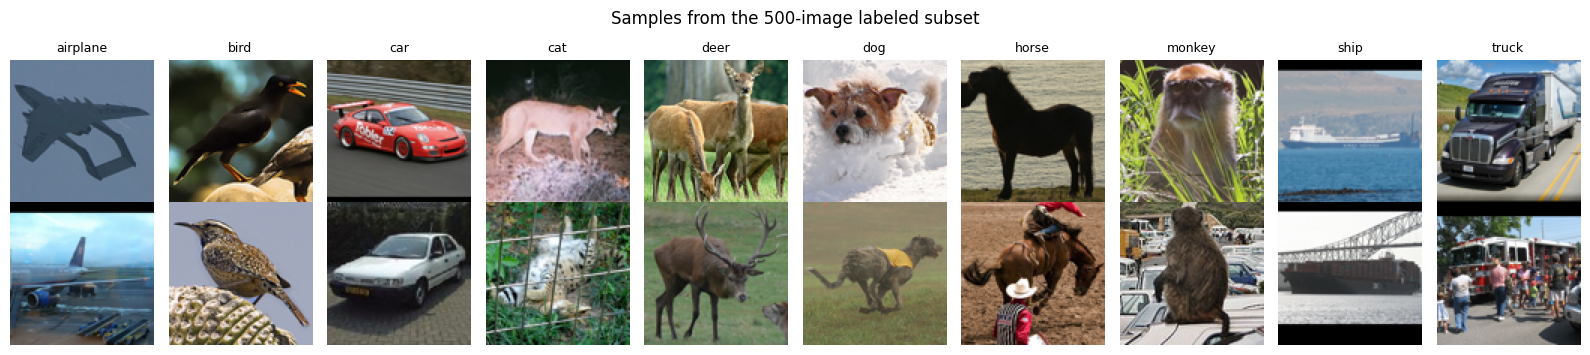

In [4]:
rng = np.random.RandomState(SEED)
y_np = y_train.numpy()
lab_idx = np.concatenate([rng.choice(np.where(y_np == c)[0], CFG["labeled_frac_per_class"], replace=False)
                          for c in range(10)])
rng.shuffle(lab_idx)
X_lab, y_lab = X_train[lab_idx], y_train[lab_idx]
np.save(f"{CKPT_DIR}/labeled_subset_idx.npy", lab_idx)

print("labeled subset:", len(lab_idx), "images | per-class counts:", np.bincount(y_lab.numpy()))

fig, axes = plt.subplots(2, 10, figsize=(16, 3.6))
for c in range(10):
    ids = np.where(y_lab.numpy() == c)[0][:2]
    for r, i in enumerate(ids):
        axes[r, c].imshow(X_lab[i].permute(1, 2, 0)); axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=9)
plt.suptitle("Samples from the 500-image labeled subset"); plt.tight_layout(); plt.show()

## Shared helpers — backbone, transforms, evaluation, linear probe

In [5]:
MEAN = torch.tensor([0.4467, 0.4398, 0.4066]).view(1, 3, 1, 1)   # STL-10 channel statistics
STD  = torch.tensor([0.2603, 0.2566, 0.2713]).view(1, 3, 1, 1)
MEAN_D, STD_D = MEAN.to(device), STD.to(device)

def to_input(xb_uint8):
    # uint8 batch on CPU -> normalized float batch on device
    x = xb_uint8.to(device, non_blocking=True).float().div_(255)
    return (x - MEAN_D) / STD_D

def make_encoder():
    # ResNet-18, NO pretrained weights; fc removed -> 512-d embedding
    m = models.resnet18(weights=None)
    m.fc = nn.Identity()
    return m

FEAT_DIM = 512

class TensorImageDataset(Dataset):
    # Dataset over a uint8 tensor. n_views=2 returns two independent augmentations (for SimCLR).
    def __init__(self, X, y=None, transform=None, n_views=1):
        self.X, self.y, self.transform, self.n_views = X, y, transform, n_views
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        img = self.X[i]
        if self.n_views == 2:
            return self.transform(img), self.transform(img)
        x = self.transform(img) if self.transform else img
        return x, (self.y[i] if self.y is not None else -1)

normalize = [T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN.flatten().tolist(), STD.flatten().tolist())]

@torch.no_grad()
def extract_features(encoder, X, bs=512):
    # 512-d embeddings for a uint8 image tensor (encoder in eval mode, no augmentation)
    encoder.eval()
    out = []
    for i in range(0, len(X), bs):
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            f = encoder(to_input(X[i:i + bs]))
        out.append(f.float().cpu())
    return torch.cat(out)

@torch.no_grad()
def evaluate_classifier(model, X, y, bs=512):
    model.eval()
    correct = 0
    for i in range(0, len(X), bs):
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(to_input(X[i:i + bs]))
        correct += (logits.argmax(1).cpu() == y[i:i + bs]).sum().item()
    return correct / len(X)

def param_checksum(module):
    return sum(p.detach().double().sum().item() for p in module.parameters())

def linear_probe(encoder, name, epochs=None, lr=5e-3):
    # Freeze the encoder; train ONLY nn.Linear(512, 10) on the 500 labeled images.
    epochs = epochs or CFG["linear_epochs"]
    encoder = encoder.to(device).eval()
    for p in encoder.parameters():
        p.requires_grad_(False)
    before = param_checksum(encoder)

    f_tr, f_te = extract_features(encoder, X_lab), extract_features(encoder, X_test)
    mu, sd = f_tr.mean(0, keepdim=True), f_tr.std(0, keepdim=True) + 1e-6   # fixed (not learned) standardization
    f_tr, f_te = ((f_tr - mu) / sd).to(device), ((f_te - mu) / sd).to(device)
    yl, yt = y_lab.to(device), y_test.to(device)

    clf = nn.Linear(FEAT_DIM, 10).to(device)
    opt = torch.optim.Adam(clf.parameters(), lr=lr, weight_decay=1e-4)
    steps = epochs * int(np.ceil(len(f_tr) / CFG["linear_bs"]))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for ep in range(1, epochs + 1):
        clf.train()
        perm = torch.randperm(len(f_tr), device=device)
        tot, correct = 0.0, 0
        for i in range(0, len(f_tr), CFG["linear_bs"]):
            idx = perm[i:i + CFG["linear_bs"]]
            logits = clf(f_tr[idx]); loss = F.cross_entropy(logits, yl[idx])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            tot += loss.item() * len(idx); correct += (logits.argmax(1) == yl[idx]).sum().item()
        if ep == 1 or ep % 5 == 0 or ep == epochs:
            print(f"[{name} linear probe] epoch {ep:2d}/{epochs}  loss {tot/len(f_tr):.3f}  train acc {correct/len(f_tr):.3f}")

    clf.eval()
    with torch.no_grad():
        test_acc = (clf(f_te).argmax(1) == yt).float().mean().item()
    assert param_checksum(encoder) == before, "encoder weights changed — it was not frozen!"
    print(f"Encoder frozen check passed (weights unchanged). {name} TEST ACCURACY: {test_acc*100:.2f}%")
    return test_acc, clf

results, histories = {}, {}

## Part A — Supervised baseline with 10% labels


In [6]:
class Classifier(nn.Module):
    def __init__(self, encoder, n_classes=10):
        super().__init__()
        self.encoder, self.head = encoder, nn.Linear(FEAT_DIM, n_classes)
    def forward(self, x):
        return self.head(self.encoder(x))

sup_tf = T.Compose([T.RandomCrop(96, padding=8, padding_mode="reflect"), T.RandomHorizontalFlip(), *normalize])
sup_loader = DataLoader(TensorImageDataset(X_lab, y_lab, sup_tf), batch_size=CFG["sup_bs"], shuffle=True,
                        num_workers=NUM_WORKERS, pin_memory=True, drop_last=False)

set_seed()
sup_model = Classifier(make_encoder()).to(device)
opt = torch.optim.Adam(sup_model.parameters(), lr=1e-3, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, CFG["sup_epochs"] * len(sup_loader))
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

hist = []
t0 = time.time()
for ep in range(1, CFG["sup_epochs"] + 1):
    sup_model.train(); tot, correct, n = 0.0, 0, 0
    for xb, yb in sup_loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = sup_model(xb); loss = F.cross_entropy(logits, yb)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item() * len(yb); correct += (logits.argmax(1) == yb).sum().item(); n += len(yb)
    hist.append(tot / n)
    print(f"[Part A] epoch {ep:2d}/{CFG['sup_epochs']}  loss {tot/n:.3f}  train acc {correct/n:.3f}  ({time.time()-t0:.0f}s)")
histories["Part A: supervised CE"] = hist

acc_A = evaluate_classifier(sup_model, X_test, y_test)
results["A: Supervised (10% labels)"] = acc_A
torch.save(sup_model.state_dict(), f"{CKPT_DIR}/partA_supervised.pt")
print(f"\nPart A TEST ACCURACY: {acc_A*100:.2f}%")

[Part A] epoch  1/15  loss 2.147  train acc 0.196  (8s)
[Part A] epoch  2/15  loss 1.793  train acc 0.314  (8s)
[Part A] epoch  3/15  loss 1.573  train acc 0.384  (9s)
[Part A] epoch  4/15  loss 1.394  train acc 0.486  (10s)
[Part A] epoch  5/15  loss 1.251  train acc 0.536  (10s)
[Part A] epoch  6/15  loss 1.221  train acc 0.582  (11s)
[Part A] epoch  7/15  loss 1.024  train acc 0.632  (11s)
[Part A] epoch  8/15  loss 0.911  train acc 0.688  (12s)
[Part A] epoch  9/15  loss 0.840  train acc 0.686  (12s)
[Part A] epoch 10/15  loss 0.620  train acc 0.790  (13s)
[Part A] epoch 11/15  loss 0.594  train acc 0.810  (14s)
[Part A] epoch 12/15  loss 0.440  train acc 0.852  (15s)
[Part A] epoch 13/15  loss 0.390  train acc 0.864  (16s)
[Part A] epoch 14/15  loss 0.356  train acc 0.896  (16s)
[Part A] epoch 15/15  loss 0.327  train acc 0.914  (17s)

Part A TEST ACCURACY: 46.81%


## Part B — Rotation prediction (self-supervised)


In [7]:
class RotationNet(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder, self.rot_head = encoder, nn.Linear(FEAT_DIM, 4)
    def forward(self, x):
        return self.rot_head(self.encoder(x))

def rotate_batch(x, k):
    # rotate each image x[i] by k[i] * 90 degrees (square images -> same shape)
    out = x.clone()
    for r in (1, 2, 3):
        m = k == r
        if m.any():
            out[m] = torch.rot90(x[m], r, dims=(2, 3))
    return out

X_rot = X_unl if CFG["rot_subset"] is None else X_unl[:CFG["rot_subset"]]
N, bs = len(X_rot), CFG["rot_bs"]
steps_per_epoch = N // bs

set_seed()
rot_model = RotationNet(make_encoder()).to(device)
opt = torch.optim.SGD(rot_model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.1, total_steps=CFG["rot_epochs"] * steps_per_epoch, pct_start=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

hist = []
t0 = time.time()
for ep in range(1, CFG["rot_epochs"] + 1):
    rot_model.train(); tot, correct, n = 0.0, 0, 0
    perm = torch.randperm(N)
    for s in range(steps_per_epoch):
        x = to_input(X_rot[perm[s * bs:(s + 1) * bs]])
        flip = torch.rand(len(x), device=device) < 0.5                    # horizontal flip
        x = torch.where(flip[:, None, None, None], x.flip(3), x)
        if CFG["rot_all_four"]:
            k = torch.arange(4, device=device).repeat_interleave(len(x))
            x = x.repeat(4, 1, 1, 1)
        else:
            k = torch.randint(0, 4, (len(x),), device=device)
        x = rotate_batch(x, k)
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = rot_model(x); loss = F.cross_entropy(logits, k)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item() * len(k); correct += (logits.argmax(1) == k).sum().item(); n += len(k)
    hist.append(tot / n)
    print(f"[Part B] epoch {ep:2d}/{CFG['rot_epochs']}  rotation loss {tot/n:.3f}  rotation acc {correct/n:.3f}  ({time.time()-t0:.0f}s)")
histories["Part B: rotation CE"] = hist
torch.save(rot_model.state_dict(), f"{CKPT_DIR}/partB_rotation.pt")

[Part B] epoch  1/15  rotation loss 1.066  rotation acc 0.544  (29s)
[Part B] epoch  2/15  rotation loss 0.799  rotation acc 0.682  (58s)
[Part B] epoch  3/15  rotation loss 0.690  rotation acc 0.728  (87s)
[Part B] epoch  4/15  rotation loss 0.626  rotation acc 0.756  (116s)
[Part B] epoch  5/15  rotation loss 0.580  rotation acc 0.774  (146s)
[Part B] epoch  6/15  rotation loss 0.541  rotation acc 0.792  (175s)
[Part B] epoch  7/15  rotation loss 0.511  rotation acc 0.803  (204s)
[Part B] epoch  8/15  rotation loss 0.482  rotation acc 0.815  (233s)
[Part B] epoch  9/15  rotation loss 0.455  rotation acc 0.828  (263s)
[Part B] epoch 10/15  rotation loss 0.429  rotation acc 0.837  (292s)
[Part B] epoch 11/15  rotation loss 0.401  rotation acc 0.847  (321s)
[Part B] epoch 12/15  rotation loss 0.368  rotation acc 0.862  (350s)
[Part B] epoch 13/15  rotation loss 0.332  rotation acc 0.876  (380s)
[Part B] epoch 14/15  rotation loss 0.298  rotation acc 0.891  (409s)
[Part B] epoch 15/15  r

### Part B — drop the rotation head, freeze the encoder, linear probe

In [8]:
rot_encoder = rot_model.encoder          # rotation head discarded
acc_B, clf_B = linear_probe(rot_encoder, "Rotation SSL")
results["B: Rotation SSL + linear"] = acc_B

[Rotation SSL linear probe] epoch  1/20  loss 1.969  train acc 0.282
[Rotation SSL linear probe] epoch  5/20  loss 0.749  train acc 0.748
[Rotation SSL linear probe] epoch 10/20  loss 0.465  train acc 0.900
[Rotation SSL linear probe] epoch 15/20  loss 0.379  train acc 0.944
[Rotation SSL linear probe] epoch 20/20  loss 0.363  train acc 0.948
Encoder frozen check passed (weights unchanged). Rotation SSL TEST ACCURACY: 53.71%


## Part C — SimCLR-style contrastive learning


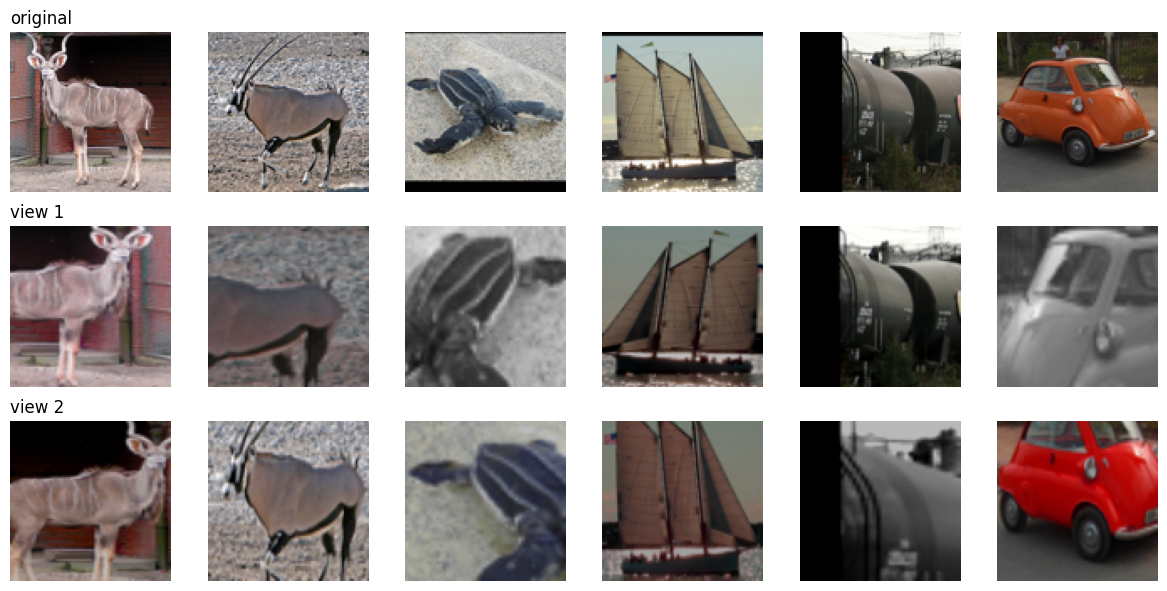

In [9]:
simclr_tf = T.Compose([
    T.RandomResizedCrop(96, scale=(0.2, 1.0), antialias=True),                       # 1. random resized crop
    T.RandomHorizontalFlip(p=0.5),                                                   # 2. horizontal flip
    T.RandomApply([T.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1)], p=0.8),  # 3. color jitter
    T.RandomGrayscale(p=0.2),                                                        # 4. grayscale
    *normalize,
])

# show two views of a few images
demo = X_unl[:6]
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
denorm = lambda t: (t * STD[0] + MEAN[0]).clamp(0, 1).permute(1, 2, 0)
for j in range(6):
    axes[0, j].imshow(demo[j].permute(1, 2, 0)); axes[1, j].imshow(denorm(simclr_tf(demo[j]))); axes[2, j].imshow(denorm(simclr_tf(demo[j])))
for a in axes.flat: a.axis("off")
axes[0, 0].set_title("original", loc="left"); axes[1, 0].set_title("view 1", loc="left"); axes[2, 0].set_title("view 2", loc="left")
plt.tight_layout(); plt.show()

In [10]:
class SimCLR(nn.Module):
    def __init__(self, encoder, proj_dim=128):
        super().__init__()
        self.encoder = encoder
        self.projector = nn.Sequential(nn.Linear(FEAT_DIM, 512), nn.BatchNorm1d(512), nn.ReLU(inplace=True),
                                       nn.Linear(512, proj_dim))
    def forward(self, x):
        return self.projector(self.encoder(x))

def nt_xent_loss(z1, z2, tau):
    # NT-Xent: cosine similarity / tau, cross-entropy over the 2N-1 other views.
    n = z1.size(0)
    z = F.normalize(torch.cat([z1, z2]).float(), dim=1)        # unit vectors -> dot product = cosine similarity
    sim = z @ z.t() / tau                                       # (2N, 2N)
    sim.fill_diagonal_(float("-inf"))                           # a view is not its own positive/negative
    targets = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    loss = F.cross_entropy(sim, targets)
    pos_top1 = (sim.argmax(1) == targets).float().mean()        # diagnostic: positive ranked first
    return loss, pos_top1

rng = np.random.RandomState(SEED)
simclr_idx = rng.choice(len(X_unl), CFG["simclr_subset"], replace=False)
X_simclr = X_unl[simclr_idx].clone()
simclr_loader = DataLoader(TensorImageDataset(X_simclr, transform=simclr_tf, n_views=2), batch_size=CFG["simclr_bs"],
                           shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
                           persistent_workers=NUM_WORKERS > 0)
print("SimCLR subset:", len(X_simclr), "images |", len(simclr_loader), "steps/epoch")

set_seed()
simclr_model = SimCLR(make_encoder()).to(device)
opt = torch.optim.AdamW(simclr_model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=CFG["simclr_epochs"] * len(simclr_loader), pct_start=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

hist = []
t0 = time.time()
for ep in range(1, CFG["simclr_epochs"] + 1):
    simclr_model.train(); tot, top1, nb = 0.0, 0.0, 0
    for v1, v2 in simclr_loader:
        v1, v2 = v1.to(device, non_blocking=True), v2.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            z = simclr_model(torch.cat([v1, v2]))               # one forward pass -> shared BatchNorm statistics
        z1, z2 = z.chunk(2)
        loss, acc = nt_xent_loss(z1, z2, CFG["tau"])
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); top1 += acc.item(); nb += 1
    hist.append(tot / nb)
    print(f"[Part C] epoch {ep:2d}/{CFG['simclr_epochs']}  NT-Xent {tot/nb:.3f}  positive top-1 {top1/nb:.3f}  ({time.time()-t0:.0f}s)")
histories["Part C: NT-Xent"] = hist
torch.save(simclr_model.state_dict(), f"{CKPT_DIR}/partC_simclr.pt")

SimCLR subset: 20000 images | 78 steps/epoch
[Part C] epoch  1/20  NT-Xent 5.324  positive top-1 0.071  (84s)
[Part C] epoch  2/20  NT-Xent 4.164  positive top-1 0.269  (163s)
[Part C] epoch  3/20  NT-Xent 3.772  positive top-1 0.385  (246s)
[Part C] epoch  4/20  NT-Xent 3.556  positive top-1 0.468  (326s)
[Part C] epoch  5/20  NT-Xent 3.395  positive top-1 0.533  (404s)
[Part C] epoch  6/20  NT-Xent 3.293  positive top-1 0.584  (481s)
[Part C] epoch  7/20  NT-Xent 3.211  positive top-1 0.621  (557s)
[Part C] epoch  8/20  NT-Xent 3.151  positive top-1 0.651  (634s)
[Part C] epoch  9/20  NT-Xent 3.094  positive top-1 0.674  (711s)
[Part C] epoch 10/20  NT-Xent 3.028  positive top-1 0.703  (785s)
[Part C] epoch 11/20  NT-Xent 2.982  positive top-1 0.717  (861s)
[Part C] epoch 12/20  NT-Xent 2.935  positive top-1 0.741  (936s)
[Part C] epoch 13/20  NT-Xent 2.899  positive top-1 0.755  (1011s)
[Part C] epoch 14/20  NT-Xent 2.866  positive top-1 0.768  (1085s)
[Part C] epoch 15/20  NT-Xent 

### Part C — drop the projection head, freeze the encoder, linear probe

In [11]:
simclr_encoder = simclr_model.encoder    # projection head discarded
acc_C, clf_C = linear_probe(simclr_encoder, "SimCLR")
results["C: SimCLR + linear"] = acc_C

[SimCLR linear probe] epoch  1/20  loss 1.659  train acc 0.396
[SimCLR linear probe] epoch  5/20  loss 0.796  train acc 0.702
[SimCLR linear probe] epoch 10/20  loss 0.589  train acc 0.784
[SimCLR linear probe] epoch 15/20  loss 0.495  train acc 0.844
[SimCLR linear probe] epoch 20/20  loss 0.477  train acc 0.856
Encoder frozen check passed (weights unchanged). SimCLR TEST ACCURACY: 56.81%


### Training curves

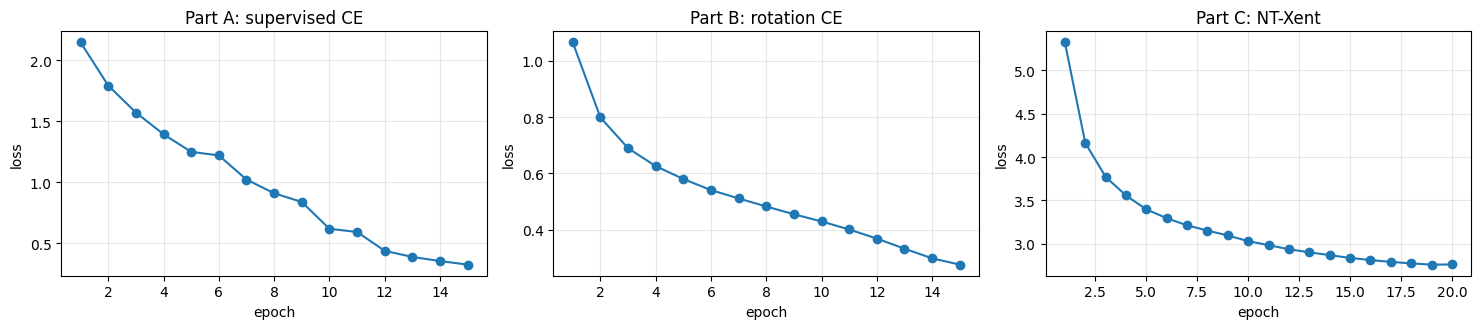

In [12]:
fig, axes = plt.subplots(1, len(histories), figsize=(5 * len(histories), 3.4))
for ax, (name, h) in zip(np.atleast_1d(axes), histories.items()):
    ax.plot(range(1, len(h) + 1), h, marker="o"); ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Part D — Nearest-neighbour retrieval in embedding space


query test indices: [989, 4207, 2657, 1110]


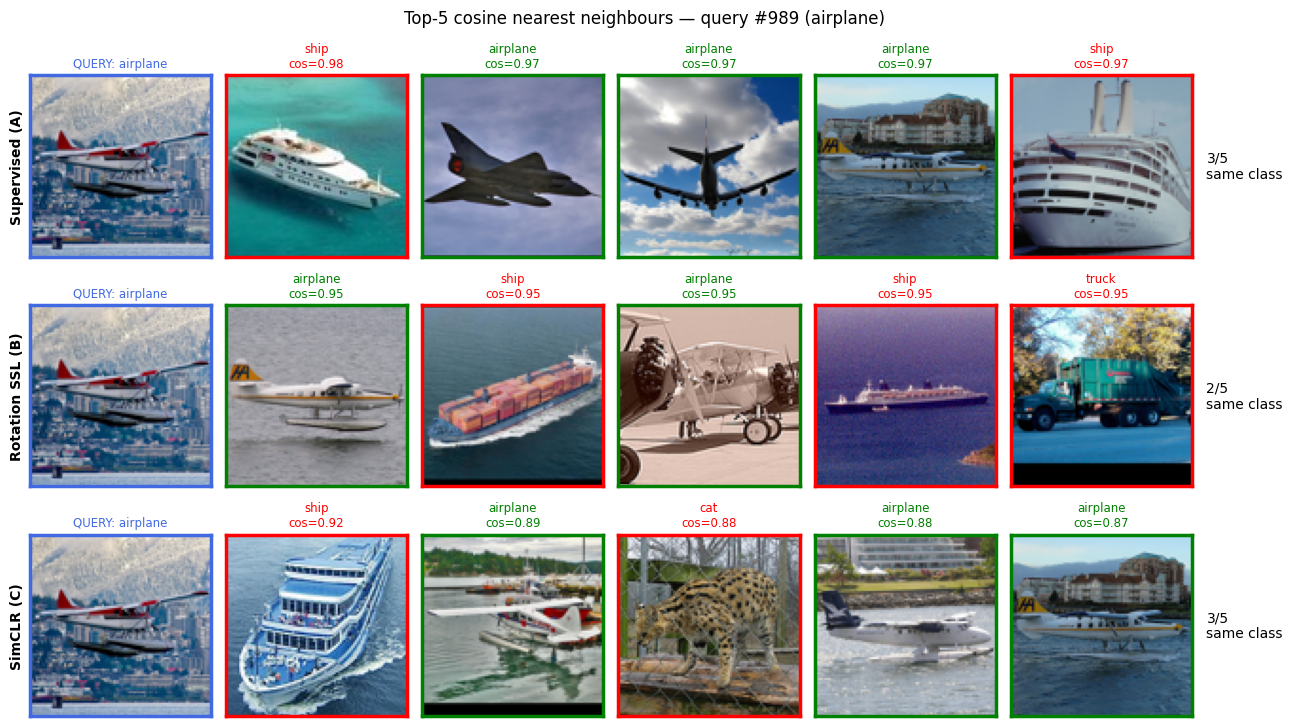

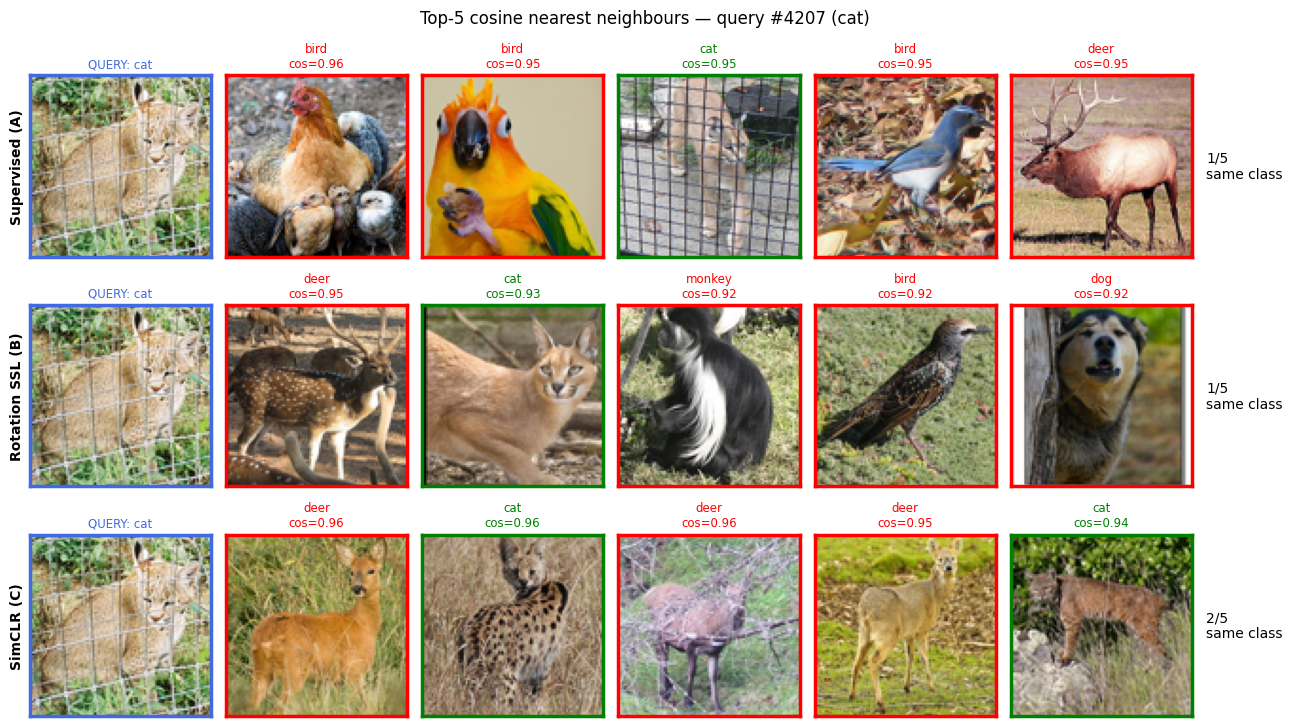

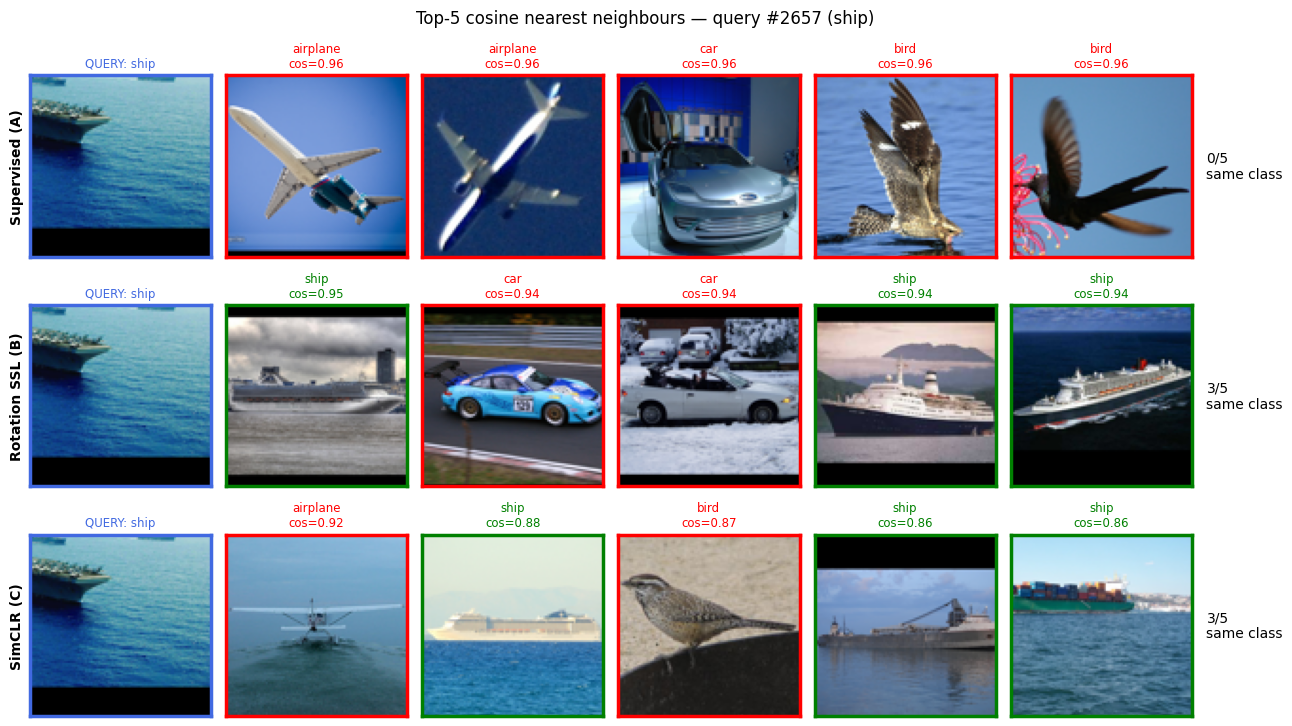

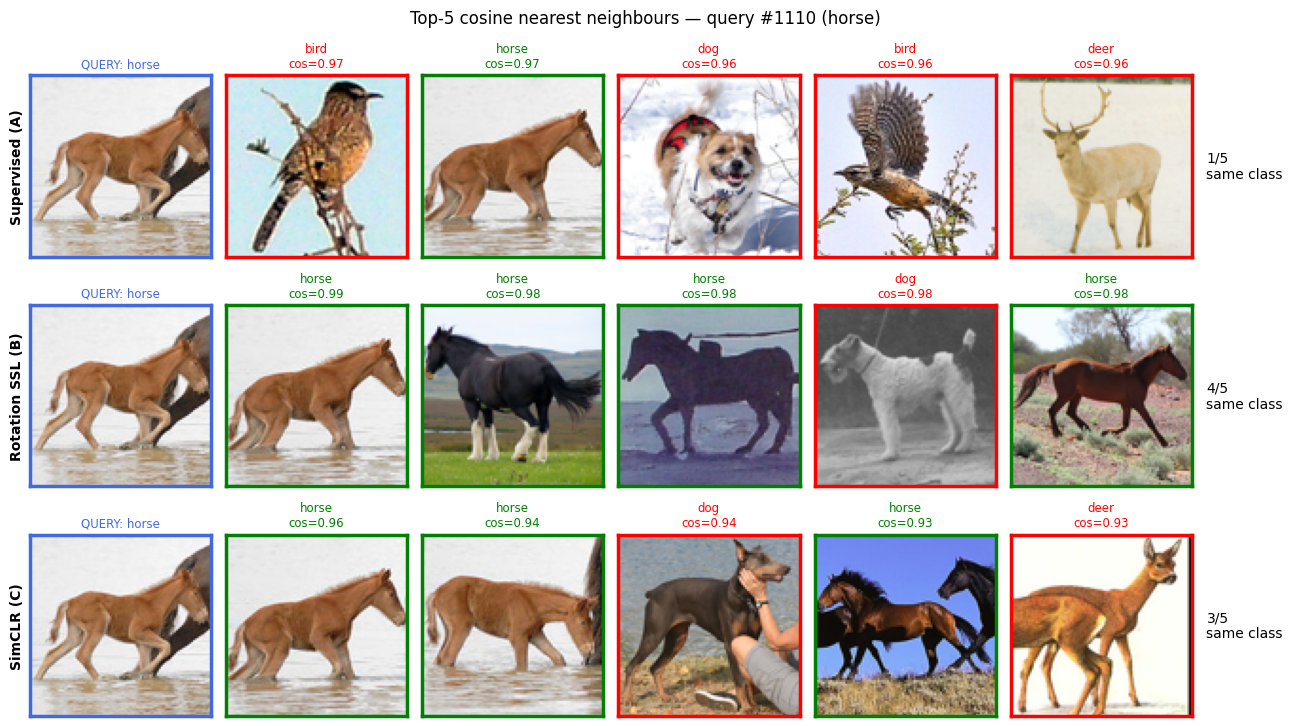

In [13]:
encoders = {
    "Supervised (A)":   sup_model.encoder,
    "Rotation SSL (B)": rot_encoder,
    "SimCLR (C)":       simclr_encoder,
}
test_emb = {name: F.normalize(extract_features(enc, X_test), dim=1) for name, enc in encoders.items()}

QUERY_CLASSES = ["airplane", "cat", "ship", "horse"]       # at least 3 required — edit freely
rng = np.random.RandomState(SEED)
query_idx = [int(rng.choice(np.where(y_test.numpy() == CLASSES.index(c))[0])) for c in QUERY_CLASSES]
print("query test indices:", query_idx)

def top_k_neighbours(E, q, k=5):
    sims = E @ E[q]              # cosine similarity (rows are unit vectors)
    sims[q] = -float("inf")      # exclude the query itself
    vals, idx = sims.topk(k)
    return idx.tolist(), vals.tolist()

def show_img(ax, i, title, color="black"):
    ax.imshow(X_test[i].permute(1, 2, 0)); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=8.5, color=color)
    for s in ax.spines.values(): s.set_edgecolor(color); s.set_linewidth(2.5)

for q in query_idx:
    q_lab = CLASSES[y_test[q]]
    fig, axes = plt.subplots(len(encoders), 6, figsize=(13, 2.5 * len(encoders)))
    for r, (name, E) in enumerate(test_emb.items()):
        nbrs, sims = top_k_neighbours(E, q)
        show_img(axes[r, 0], q, f"QUERY: {q_lab}", "royalblue")
        axes[r, 0].set_ylabel(name, fontsize=10, fontweight="bold")
        hits = 0
        for j, (i, s) in enumerate(zip(nbrs, sims), start=1):
            lab = CLASSES[y_test[i]]; ok = lab == q_lab; hits += ok
            show_img(axes[r, j], i, f"{lab}\ncos={s:.2f}", "green" if ok else "red")
        axes[r, 5].text(1.08, 0.5, f"{hits}/5\nsame class", transform=axes[r, 5].transAxes, va="center", fontsize=10)
    fig.suptitle(f"Top-5 cosine nearest neighbours — query #{q} ({q_lab})", fontsize=12)
    plt.tight_layout(); plt.show()

### Quantitative check: neighbour precision@5 over the whole test set
For every test image, the fraction of its 5 nearest neighbours sharing its label (a k-NN measure of how well each embedding clusters classes).

In [14]:
@torch.no_grad()
def precision_at_k(E, labels, k=5, chunk=1000):
    E, labels = E.to(device), labels.to(device)
    hits = 0.0
    for i in range(0, len(E), chunk):
        sims = E[i:i + chunk] @ E.t()
        rows = torch.arange(sims.size(0), device=device)
        sims[rows, rows + i] = -float("inf")                    # exclude self
        nbr = sims.topk(k, dim=1).indices
        hits += (labels[nbr] == labels[i:i + chunk, None]).float().sum().item()
    return hits / (len(E) * k)

p5 = {name: precision_at_k(E, y_test) for name, E in test_emb.items()}
for name, v in p5.items():
    print(f"{name:18s} precision@5 = {v*100:.2f}%   (chance = 10%)")

Supervised (A)     precision@5 = 39.53%   (chance = 10%)
Rotation SSL (B)   precision@5 = 45.17%   (chance = 10%)
SimCLR (C)         precision@5 = 49.87%   (chance = 10%)


## Results summary

,Model,Pre-training data,Labeled images,Evaluation,Test accuracy (%),NN precision@5 (%)
0,Supervised (A),—,500,end-to-end fine-tune,46.81,39.53
1,Rotation SSL (B),"100,000 unlabeled",500,frozen + linear,53.71,45.17
2,SimCLR (C),"20,000 unlabeled",500,frozen + linear,56.81,49.87


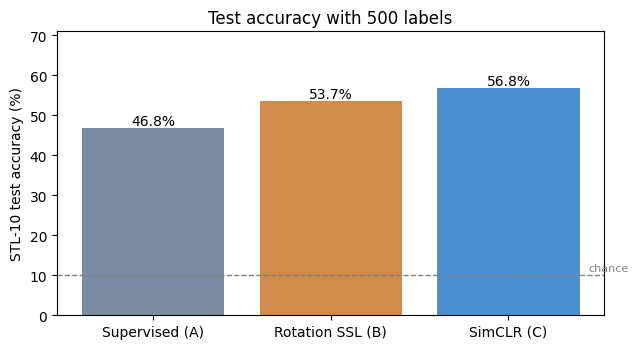

Ranking by test accuracy: SimCLR (C) (56.81%) > Rotation SSL (B) (53.71%) > Supervised (A) (46.81%)


In [15]:
summary = pd.DataFrame({
    "Model": ["Supervised (A)", "Rotation SSL (B)", "SimCLR (C)"],
    "Pre-training data": ["—", f"{len(X_rot):,} unlabeled", f"{CFG['simclr_subset']:,} unlabeled"],
    "Labeled images": [len(X_lab)] * 3,
    "Evaluation": ["end-to-end fine-tune", "frozen + linear", "frozen + linear"],
    "Test accuracy (%)": [round(results["A: Supervised (10% labels)"] * 100, 2),
                          round(results["B: Rotation SSL + linear"] * 100, 2),
                          round(results["C: SimCLR + linear"] * 100, 2)],
    "NN precision@5 (%)": [round(p5[n] * 100, 2) for n in encoders],
})
display(summary)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(summary["Model"], summary["Test accuracy (%)"], color=["#7a8ca3", "#d08c4a", "#4a8fd0"])
ax.bar_label(bars, fmt="%.1f%%"); ax.axhline(10, ls="--", c="gray", lw=1); ax.text(2.45, 11, "chance", fontsize=8, c="gray")
ax.set_ylabel("STL-10 test accuracy (%)"); ax.set_title("Test accuracy with 500 labels"); ax.set_ylim(0, max(summary["Test accuracy (%)"]) * 1.25)
plt.tight_layout(); plt.show()

ranked = summary.sort_values("Test accuracy (%)", ascending=False)
print("Ranking by test accuracy:", " > ".join(f"{m} ({a}%)" for m, a in zip(ranked["Model"], ranked["Test accuracy (%)"])))

## Analysis and discussion

### Results
| Model | Pre-training | Evaluation | Train acc. (final epoch) | **Test acc.** | NN precision@5 |
|---|---|---|---|---|---|
| Supervised (A) | none | end-to-end, 500 labels | 91.4% | **46.81%** | 39.53% |
| Rotation SSL (B) | 100,000 unlabeled, 15 epochs | frozen encoder + linear | 94.8% | **53.71%** | 45.17% |
| SimCLR (C) | 20,000 unlabeled, 20 epochs | frozen encoder + linear | 85.6% | **56.81%** | 49.87% |

Chance is 10% for both metrics. Ranking: **SimCLR > Rotation SSL > Supervised**. Nearest-neighbour precision@5 ranks the models in the same order as test accuracy.

### 1. Which model performed best, and why?
**SimCLR performed best, with 56.81% test accuracy.** That is 10.0 points above the supervised baseline and 3.1 points above rotation, even though its encoder was frozen and only one linear layer ever saw the labels.

The contrastive objective explains this. SimCLR has to pull two heavily augmented views of the same image together, and push them away from the other 510 views in the batch. To do that, the encoder must ignore what the augmentations change (crop position and scale, left/right orientation, colour, saturation) and keep what stays the same: object shape, parts and texture. Those are largely the features that define an STL-10 class. The low temperature (τ = 0.2) sharpens the softmax, which focuses the gradient on the hardest negatives. The large number of negatives spreads embeddings across the hypersphere, so the classes become close to linearly separable.

SimCLR was also the most **data-efficient** model. It saw 5× fewer unlabeled images than rotation (20k vs 100k) and took about 4× fewer optimizer steps (1,560 vs 5,850), yet still produced the best features. During pre-training, its positive-pair top-1 accuracy rose from 7% to 81%.

SimCLR also had the **smallest gap between train and test accuracy**: 85.6% train vs 56.8% test, a 29-point gap. Rotation's gap was 41 points and supervised's was 45. This means its features generalise rather than memorise: the 500 labeled images are harder to fit perfectly with SimCLR features, but what the classifier learns carries over to new images.

### 2. Why did the other models perform as they did?
**Supervised, 10% labels (46.81%).** A ResNet-18 has about 11 M parameters. Here it was trained from scratch on 500 images (50 per class) for 15 epochs, which is only about 120 gradient steps. Its training accuracy climbed to 91.4% while test accuracy stayed at 46.8%. That 45-point gap shows clear overfitting: the network memorised the 500 images instead of learning general visual features. It also never sees the 100,000 unlabeled images, so its visual experience is limited to those 500 photos. It had the lowest precision@5 (39.5%), so its embedding space clusters classes the least.

**Rotation SSL (53.71%).** Rotation pre-training beat the supervised baseline by 6.9 points, which shows that 100k images of self-supervised pre-training produce better features than end-to-end training on 500 labels. To predict whether an image is upright, the network must recognise objects and where they are in the scene, so its features carry semantic information.

It still trails SimCLR, for three reasons:
- **Shortcuts:** the pretext task can be partly solved with low-level cues such as sky at the top, ground at the bottom, horizon lines and lighting direction. Those cues help with rotation but not with telling a cat from a dog.
- **Last-layer specialisation:** the final-layer features become specialised for rotation. The linear classifier reached 94.8% train accuracy but only 53.7% test, so the features fit the 500 labeled images easily without generalising as well. Rotation-trained networks are known to give better linear-probe results from intermediate layers.
- **Ambiguous classes:** orientation is unclear for some STL-10 images, such as airplanes and birds photographed against open sky.

Rotation accuracy was still climbing at the end of training (rotation loss 0.298 → 0.276 over the last two epochs, rotation accuracy 89.9%), so the encoder had not converged within 15 epochs.

### 3. What changes could improve each model?
- **Supervised:**
  - stronger augmentation (RandAugment, mixup/CutMix, random erasing) and label smoothing to reduce the overfitting
  - a held-out validation split with early stopping
  - a CIFAR-style ResNet stem (3×3 first convolution, no max-pool) better suited to 96×96 images
  - semi-supervised methods such as pseudo-labelling or FixMatch, which make use of the 100k unlabeled images
  - initialising from the SimCLR encoder and fine-tuning end-to-end
- **Rotation SSL:**
  - more epochs, since the loss was still decreasing
  - all four rotations of each image in every batch
  - stronger augmentation before rotating, to block the low-level shortcuts
  - a linear probe on an intermediate layer (e.g. pooled `layer3` features)
  - combining rotation with a second pretext task
- **SimCLR:**
  - many more epochs (SimCLR usually trains for hundreds) and all 100k unlabeled images instead of 20k
  - larger batches, or a MoCo-style queue, for more negatives
  - Gaussian blur, as in the original SimCLR augmentation set
  - tuning τ in the 0.1–0.5 range
  - LARS with a larger learning rate
  - moving augmentation onto the GPU: Part C took 26 minutes, mostly in CPU data loading
  - fine-tuning the encoder end-to-end after the linear probe
- **All three:** repeating each run with several seeds and reporting mean ± std, since a 3-point difference from a single run is meaningful but not certain.

### 4. What did the nearest-neighbour visualisations reveal?
| Query | Supervised (A) | Rotation (B) | SimCLR (C) |
|---|---|---|---|
| airplane | _/5 | _/5 | _/5 |
| cat | _/5 | _/5 | _/5 |
| ship | _/5 | _/5 | 3/5 |
| horse (#1110) | 1/5 | 4/5 | 3/5 |

Over the whole 8,000-image test set, **SimCLR embeddings had the highest neighbour precision@5 (49.87%)**, followed by rotation (45.17%) and supervised (39.53%). This matches the linear-probe ranking. An encoder that places same-class images close together in cosine space is what lets a linear classifier work with only 500 labels. The individual queries are noisier than this average, though: for the horse query, rotation (4/5) actually beat SimCLR (3/5). Four queries are only a snapshot, which is why the precision@5 over all 8,000 images is the more reliable comparison.

**Horse query (#1110), a brown foal walking through water against a pale background:**
- **Supervised (1/5):** only one neighbour was a horse. The other four were two birds, a dog in snow and a deer, and every one of them has a bright, white or pale background. The supervised encoder matched the *background and overall brightness* rather than the animal, which is what you would expect from a network that overfit 500 images and latched onto easy low-level cues.
- **Rotation (4/5):** four horses, including a black horse on grass and a dark horse on dirt, so it recognised the horse's shape across different colours and settings. Its one error was a dog: another four-legged animal standing upright and side-on. That fits the rotation objective, which rewards knowing an animal's upright body layout.
- **SimCLR (3/5):** three horses, and its two errors were a dog and a deer. Both are four-legged animals with a similar body shape, which are reasonable, *semantic* mistakes rather than background matches. Two of its horse neighbours have a different background and colour from the query, which shows the colour and crop invariance its augmentations teach.
- The highest-similarity neighbours (cos ≈ 0.96–0.99) for rotation and SimCLR are near-identical frames of the same foal. STL-10 contains near-duplicate images, and both self-supervised encoders find them reliably.

**Ship query, SimCLR (3/5):** three ships, plus an airplane over water and a bird. The airplane error shows that SimCLR still partly relies on scene context: blue water and sky are a strong cue shared by ships, seaplanes and seabirds.

**Overall:** supervised neighbours were driven by background and brightness, rotation neighbours by object shape and upright layout, and SimCLR neighbours by object category with some reliance on scene context. All three encoders are well above chance (10%), but none is close to perfect. A 50% precision@5 means that even for SimCLR, about half of each image's nearest neighbours come from a different class, which leaves clear room for the improvements listed in section 3.